<a href="https://colab.research.google.com/github/Melibelibob/DSC110/blob/main/data_summarization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("https://raw.githubusercontent.com/osoliman/DSC110/refs/heads/main/Datasets/nhanes_final.csv")

In [5]:
df.head()

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN


transforming variables

In [6]:
df['education'].unique()

array([ 5.,  3., nan,  2.,  4.,  1.,  9.])

In [8]:
education_map={
    1:'les than 9th grade',
    2:'9-11th grade',
    3:'high school grad',
    4:'some college or AA degree',
    5:'college grad',
    9:'do not know'
}

In [9]:
df['education_label']=df['education'].map(education_map)

In [10]:
df.head()

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose,education_label
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0,college grad
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0,college grad
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0,high school grad
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN,NaN
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN


In [11]:
df['education_label'].value_counts()

,count
education_label,
college grad,2625
some college or AA degree,2370
high school grad,1749
9-11th grade,666
les than 9th grade,373
do not know,11


In [17]:
#do the same for has_diabetes field
#1=has diabetes, 2= no diabetes, 3=borderline, 9= dont know
#name the new field diabetes_label
diabetes_label={
    1:'has diabetes',
    2:'no diabetes',
    3:'borderline',
    9:'do not know'
}

In [19]:
df['diabetes_label']=df['has_diabetes'].map(diabetes_label)

In [24]:
df.head()

,id,gender,age,race_ethnicity,education,bmi,height_cm,systolic_bp,has_diabetes,hba1c,fasting_glucose,education_label,diabetes_label
0,130378.0,1.0,43.0,6.0,5.0,27.0,179.5,135.0,2.0,5.6,113.0,college grad,no diabetes
1,130379.0,1.0,66.0,3.0,5.0,33.5,174.2,121.0,2.0,5.6,99.0,college grad,no diabetes
2,130380.0,2.0,44.0,2.0,3.0,29.7,152.9,111.0,1.0,6.2,156.0,high school grad,has diabetes
3,130381.0,2.0,5.0,7.0,NaN,23.8,120.1,NaN,2.0,NaN,NaN,NaN,no diabetes
4,130382.0,1.0,2.0,3.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,no diabetes


In [25]:
df['diabetes_label'].value_counts()

,count
diabetes_label,
no diabetes,10371
has diabetes,1081
borderline,284
do not know,4


In [30]:
#data summarization
#one numerical value
#numerical variables in our data

avg_age= round (df['age'].mean(),2)
print(f"the average age of NHANES respondents is {avg_age}")

the average age of NHANES respondents is 38.32


In [31]:
df['age'].std()

25.60199011389104

In [33]:
df['age'].median()

37.0

In [34]:
df['age'].quantile([0.25])

,age
0.25,13.0


In [35]:
df['age'].quantile([0.75])

,age
0.75,62.0


In [36]:
df['age'].describe()

,age
count,1.193300e+04
mean,3.831786e+01
std,2.560199e+01
min,5.397605e-79
25%,1.300000e+01
50%,3.700000e+01
75%,6.200000e+01
max,8.000000e+01


In [39]:
df['age'].describe().apply(lambda x:format(x,'f'))

,age
count,11933.000000
mean,38.317858
std,25.601990
min,0.000000
25%,13.000000
50%,37.000000
75%,62.000000
max,80.000000


In [43]:
df['age'].mode()

,age
0,80.0


<Axes: >

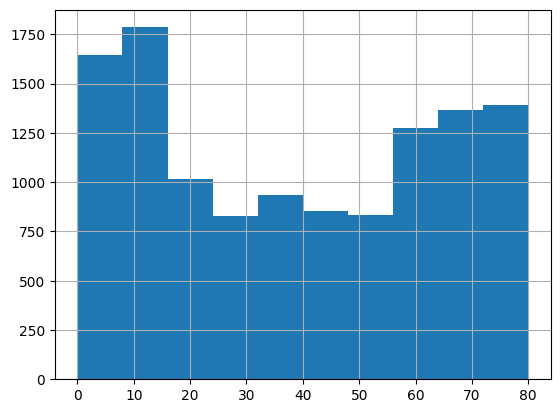

In [45]:
#data visualization for one numeric value
df['age'].hist()

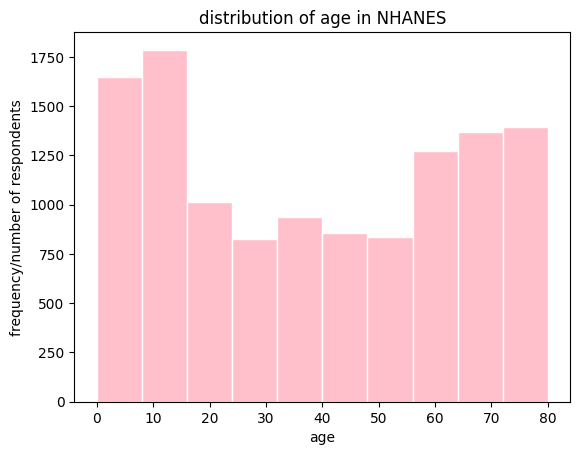

In [57]:

df['age'].hist(edgecolor='white',color='pink')
plt.title ("distribution of age in NHANES")
plt.ylabel ("frequency/number of respondents")
plt.xlabel ("age")
plt.grid(False)

summarizing and visualizing of one categorical/quanlitative variable


In [58]:
df['education_label'].value_counts()

,count
education_label,
college grad,2625
some college or AA degree,2370
high school grad,1749
9-11th grade,666
les than 9th grade,373
do not know,11


In [59]:
df['education_label'].value_counts(normalize=True)*100

,proportion
education_label,
college grad,33.679754
some college or AA degree,30.408006
high school grad,22.440339
9-11th grade,8.545035
les than 9th grade,4.785733
do not know,0.141134


Text(0, 0.5, 'Number of respondents/frequency')

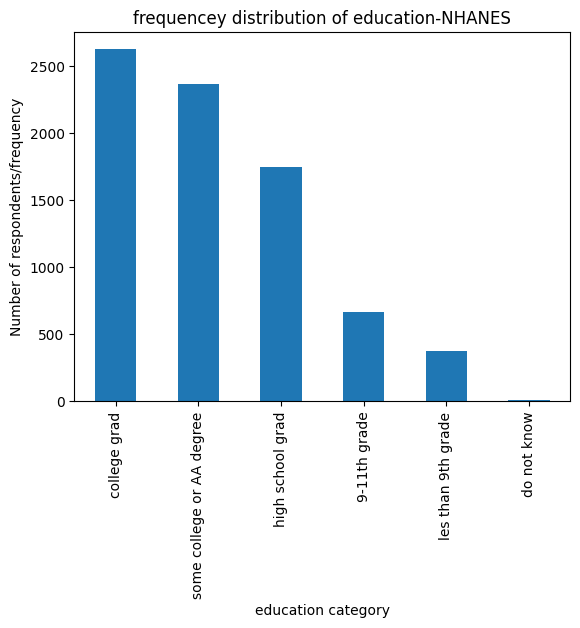

In [64]:
df["education_label"].value_counts().plot(kind='bar')
plt.title('frequencey distribution of education-NHANES')
plt.xlabel('education category')
plt.ylabel('Number of respondents/frequency')

two numerical variables

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

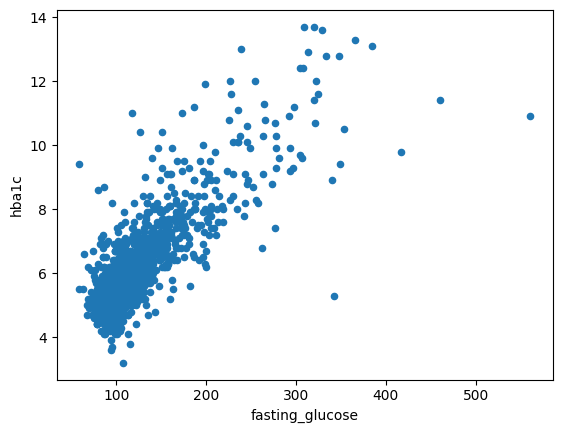

In [69]:
df.plot(x='fasting_glucose',y='hba1c', kind ='scatter')

<Axes: xlabel='fasting_glucose', ylabel='hba1c'>

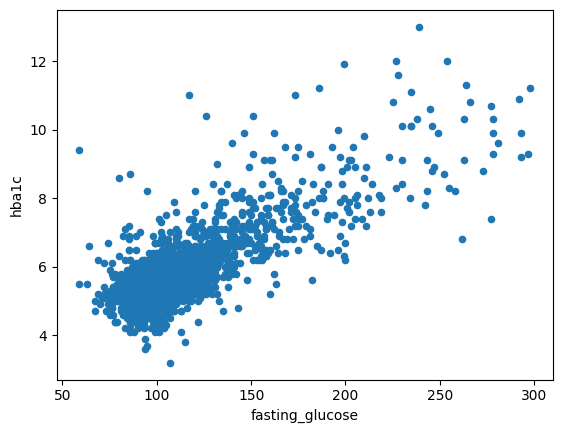

In [72]:
df_no_outliers=df[df['fasting_glucose']<300]
df_no_outliers.plot(x='fasting_glucose', y='hba1c', kind='scatter')

2 categorical variables

In [76]:
df['bmi_category']= pd.cut(df['bmi'],
                          bins =[0,18.5,25,30,100],
                          labels = ['underweight', 'normal', 'overweight','obese']
                          )

In [81]:
pd.crosstab(df['bmi_category'], df ['diabetes_label'], normalize='index')*100

diabetes_label,borderline,do not know,has diabetes,no diabetes
bmi_category,,,,
underweight,0.000000,0.082237,0.328947,99.588816
normal,1.625000,0.041667,4.541667,93.791667
overweight,3.197807,0.000000,10.644130,86.158063
obese,4.501125,0.000000,18.904726,76.594149


<Axes: xlabel='bmi_category'>

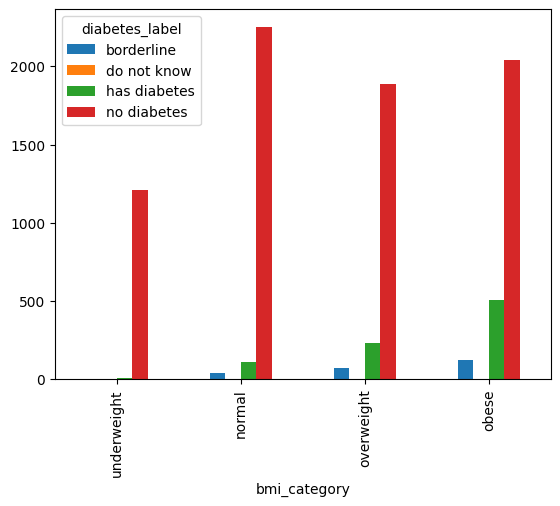

In [83]:
pd.crosstab(df['bmi_category'], df['diabetes_label']).plot(kind='bar')

one numerical and one categorical

In [84]:
df.groupby('diabetes_label')['bmi'].mean()

,bmi
diabetes_label,
borderline,32.068559
do not know,19.250000
has diabetes,32.981412
no diabetes,26.439797


Text(0, 0.5, 'bmi')

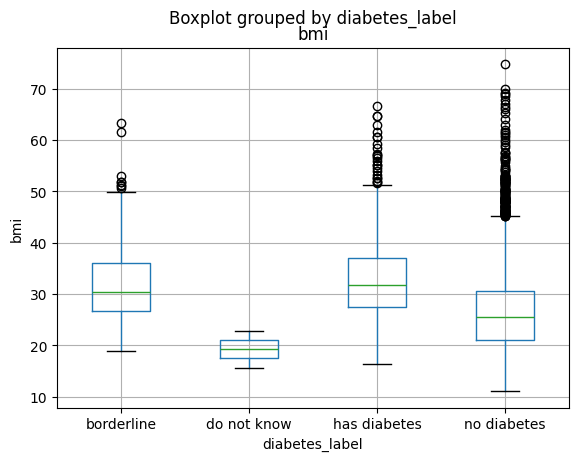

In [86]:
#boxplot
df.boxplot(column='bmi', by='diabetes_label')
plt.ylabel('bmi')